# Grammy Awards Database — Exploratory Data Analysis (EDA)

In [ ]:
from pathlib import Path
import sys

import pandas as pd
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

project_root = next(
    parent
    for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "src" / "spotify_grammys_etl").is_dir()
)
sys.path.insert(0, str(project_root / "src"))
from spotify_grammys_etl.config import get_config


## Database Connection & Configuration

In [ ]:
# MySQL Grammy Awards; credentials are loaded from the project environment.
engine = get_config().mysql_engine()

# Test connection
with engine.connect() as connection:
    version = connection.execute(
        text("SELECT VERSION()")
    ).scalar()

    print("Connected successfully!")
    print("MySQL version:", version)


Connected successfully!
MySQL version: 8.0.46


In [ ]:
with engine.connect() as connection:
    databases = pd.read_sql(
        text("SHOW DATABASES"),
        connection
    )

display(databases)

,Database
0,grammys
1,information_schema
2,mysql
3,performance_schema
4,sys


In [ ]:
engine = get_config().mysql_engine()

with engine.connect() as connection:
    tables = pd.read_sql(
        text("SHOW TABLES FROM grammys"),
        connection
    )

display(tables)


,Tables_in_grammys
0,awards


In [ ]:
engine = get_config().mysql_engine()


In [ ]:

df = pd.read_sql("SELECT * FROM awards LIMIT 10", engine)
df.head()

,year,title,published_at,updated_at,category,nominee,artist,workers,img,winner
0,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Bad Guy,Billie Eilish,"Finneas O'Connell, producer; Rob Kinelski & Fi...",https://www.grammy.com/sites/com/files/styles/...,True
1,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,"Hey, Ma",Bon Iver,"BJ Burton, Brad Cook, Chris Messina & Justin V...",https://www.grammy.com/sites/com/files/styles/...,True
2,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,7 rings,Ariana Grande,"Charles Anderson, Tommy Brown, Michael Foster ...",https://www.grammy.com/sites/com/files/styles/...,True
3,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Hard Place,H.E.R.,"Rodney “Darkchild” Jerkins, producer; Joseph H...",https://www.grammy.com/sites/com/files/styles/...,True
4,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Talk,Khalid,"Disclosure & Denis Kosiak, producers; Ingmar C...",https://www.grammy.com/sites/com/files/styles/...,True


## Dataset Overview & Data Quality Assessment

In [ ]:
# Load the database table into a Pandas DataFrame
df_awards = pd.read_sql("SELECT * FROM awards", engine)

# Column names and data types
print("Column names and data types:")
print(df_awards.dtypes)

# Missing values
print("\nMissing values per column:")
print(df_awards.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df_awards.duplicated().sum())

# Number of rows and columns
rows, columns = df_awards.shape

print(f"\nNumber of rows: {rows}")
print(f"Number of columns: {columns}")

Column names and data types:
year             int64
title           object
published_at    object
updated_at      object
category        object
nominee         object
artist          object
workers         object
img             object
winner          object
dtype: object

Missing values per column:
year            0
title           0
published_at    0
updated_at      0
category        0
nominee         0
artist          0
workers         0
img             0
winner          0
dtype: int64

Duplicate records: 0

Number of rows: 4810
Number of columns: 10


Missing Values and Empty Strings Analysis

The initial missing-value assessment reported zero missing values across all columns. However, a further inspection revealed empty strings in several columns.

This difference occurs because Pandas treats null values, such as NaN and None, differently from empty strings (""). The isnull() method detects null values but does not identify empty strings as missing data.

In [ ]:
# Missing values in MySQL data
print("Missing values per column:")
print(df_awards.isnull().sum())

print("\nEmpty strings per column:")
print(df_awards.astype("string").apply(
    lambda col: col.str.strip().eq("").sum()
))

Missing values per column:
year            0
title           0
published_at    0
updated_at      0
category        0
nominee         0
artist          0
workers         0
img             0
winner          0
dtype: int64

Empty strings per column:
year               0
title              0
published_at       0
updated_at         0
category           0
nominee            6
artist          1840
workers         2190
img             1367
winner             0
dtype: int64


# Top 20 artists by frequency 

In [ ]:
query = text("""
    SELECT
        artist,
        COUNT(*) AS frequency
    FROM awards
    WHERE artist IS NOT NULL
      AND TRIM(artist) <> ''
    GROUP BY artist
    ORDER BY frequency DESC
    LIMIT 20;
""")

with engine.connect() as conn:
    top_20_artists = pd.read_sql(query, conn)

top_20_artists

,artist,frequency
0,(Various Artists),66
1,U2,18
2,Aretha Franklin,16
3,Ella Fitzgerald,13
4,Bruce Springsteen,13
5,Stevie Wonder,13
6,Beyoncé,13
7,Tony Bennett,12
8,Jimmy Sturr,12
9,Ray Charles,12


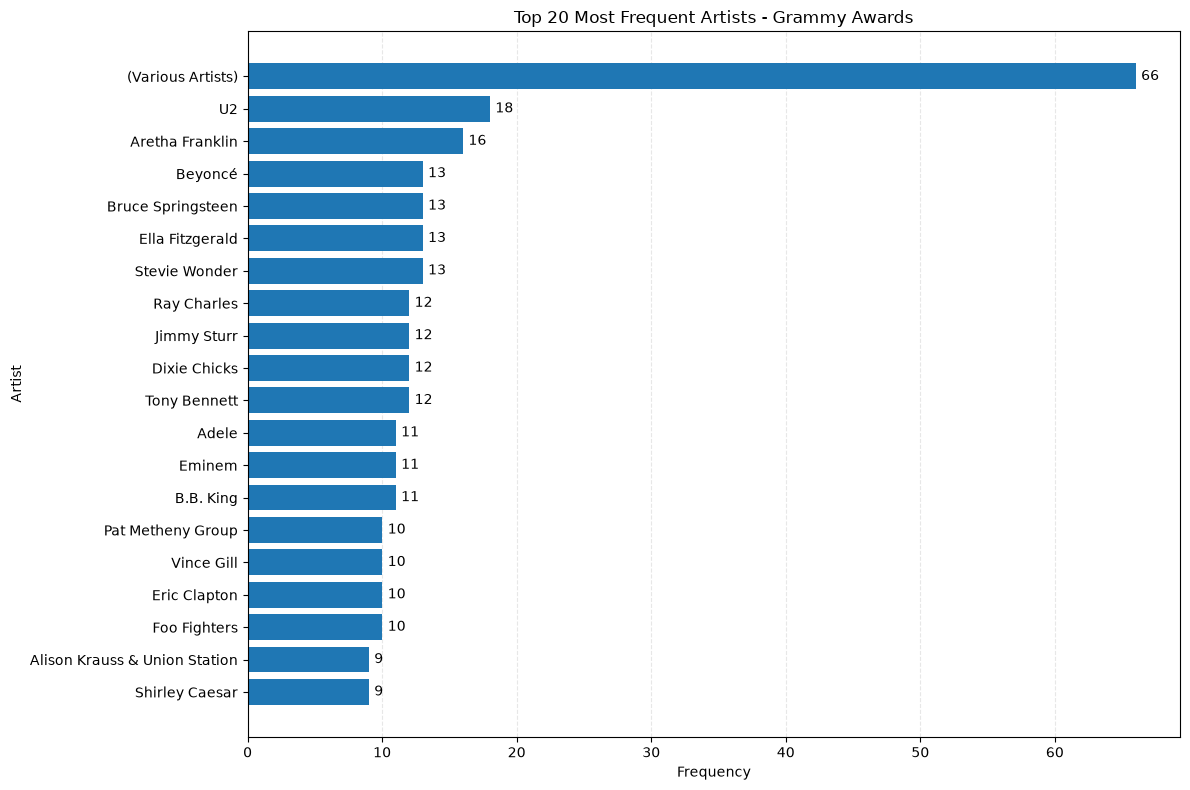

In [ ]:

query = text("""
    SELECT
        artist,
        COUNT(*) AS frequency
    FROM awards
    WHERE artist IS NOT NULL
      AND TRIM(artist) <> ''
    GROUP BY artist
    ORDER BY frequency DESC
    LIMIT 20;
""")

with engine.connect() as conn:
    top_20_artists = pd.read_sql(query, conn)

# Frequency diagram
top_20_artists = top_20_artists.sort_values("frequency")

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_20_artists["artist"],
    top_20_artists["frequency"]
)

# Add frequency labels
ax.bar_label(bars, padding=4, fmt="%d")

# Chart labels and title
ax.set_title("Top 20 Most Frequent Artists - Grammy Awards")
ax.set_xlabel("Frequency")
ax.set_ylabel("Artist")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


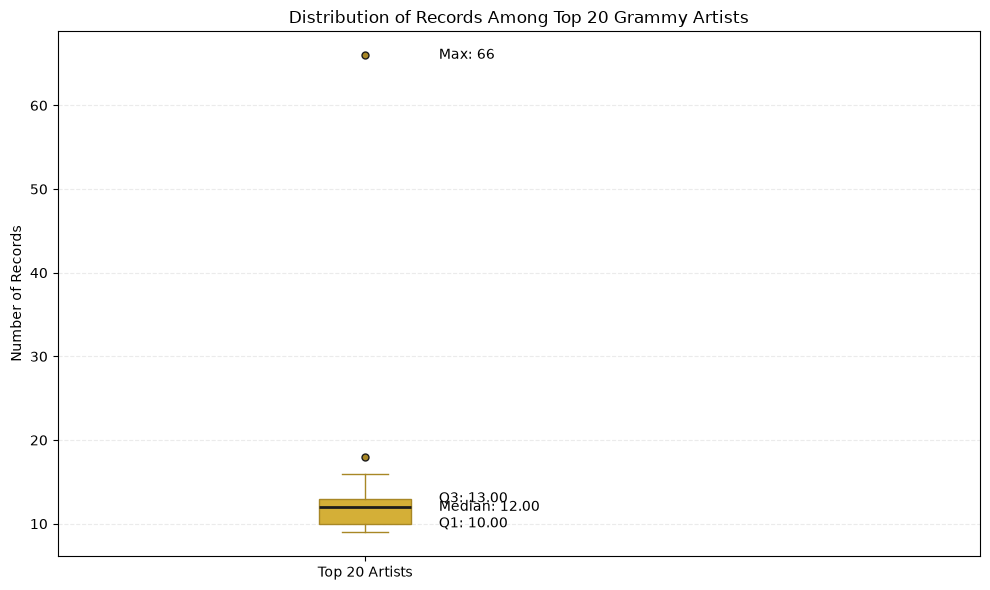

In [ ]:
# Load artist frequencies from MySQL
query = text("""
    SELECT
        artist,
        COUNT(*) AS frequency
    FROM grammys.awards
    WHERE artist IS NOT NULL
      AND TRIM(artist) <> ''
    GROUP BY artist
    ORDER BY frequency DESC
    LIMIT 20;
""")

with engine.connect() as conn:
    top_20_artists = pd.read_sql(query, conn)

# Prepare data
data = top_20_artists["frequency"].dropna()

# Calculate statistics
Q1 = data.quantile(0.25)
median = data.median()
Q3 = data.quantile(0.75)
maximum = data.max()

# Grammy-inspired colours
gold = "#D4AF37"
black = "#1C1C1C"
dark_gold = "#A88725"

# Create boxplot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    data,
    patch_artist=True,
    boxprops=dict(facecolor=gold, color=dark_gold),
    medianprops=dict(color=black, linewidth=2),
    whiskerprops=dict(color=dark_gold),
    capprops=dict(color=dark_gold),
    flierprops=dict(
        marker="o",
        markerfacecolor=dark_gold,
        markeredgecolor=black,
        markersize=5
    )
)

# Display statistics
ax.text(1.12, Q1, f"Q1: {Q1:,.2f}", va="center")
ax.text(1.12, median, f"Median: {median:,.2f}", va="center")
ax.text(1.12, Q3, f"Q3: {Q3:,.2f}", va="center")
ax.text(1.12, maximum, f"Max: {maximum:,.0f}", va="center")

# Titles and labels
ax.set_title("Distribution of Records Among Top 20 Grammy Artists")
ax.set_ylabel("Number of Records")
ax.set_xticks([1])
ax.set_xticklabels(["Top 20 Artists"])

ax.set_xlim(0.5, 2.0)
ax.grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()


**Data Quality Issue:** `(Various Artists)` does not identify a specific artist; instead, it serves as a label representing multiple artists.

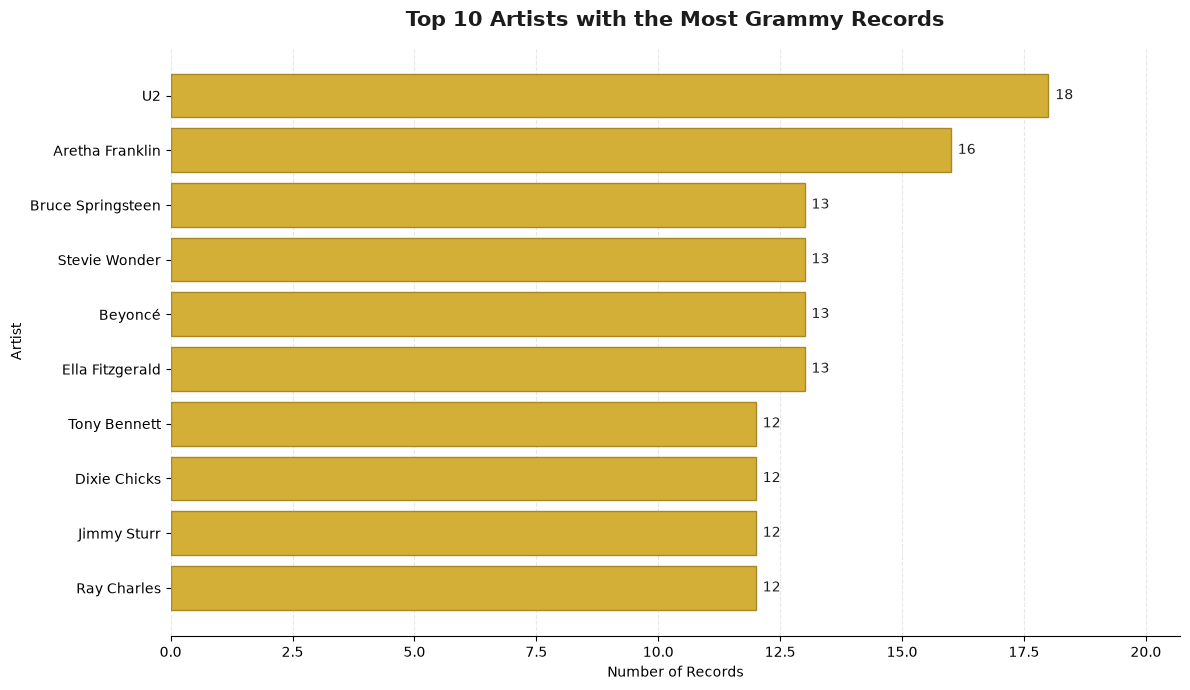

In [ ]:
# Top 10 artists by record frequency
query = text("""
    SELECT
        artist,
        COUNT(*) AS frequency
    FROM awards
    WHERE artist IS NOT NULL
      AND TRIM(artist) <> ''
      AND artist <> '(Various Artists)'
    GROUP BY artist
    ORDER BY frequency DESC
    LIMIT 10;
""")

with engine.connect() as conn:
    top_10_artists = pd.read_sql(query, conn)

# Sort for horizontal bar chart
top_10_artists = top_10_artists.sort_values("frequency")

# Grammy-inspired colours
gold = "#D4AF37"
dark_gold = "#A88725"
black = "#1C1C1C"

# Create chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_artists["artist"],
    top_10_artists["frequency"],
    color=gold,
    edgecolor=dark_gold
)

# Add frequency labels
ax.bar_label(bars, padding=5, fmt="%d", color=black)

# Titles and labels
ax.set_title(
    "Top 10 Artists with the Most Grammy Records",
    fontsize=15,
    fontweight="bold",
    color=black,
    pad=15
)
ax.set_xlabel("Number of Records")
ax.set_ylabel("Artist")

# Styling
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.set_xlim(0, top_10_artists["frequency"].max() * 1.15)

plt.tight_layout()
plt.show()


The year column has continuous temporal coverage, with no missing years between 1958 and 2019. This confirms that every year in the observed range is represented in the dataset.

In [ ]:
# Check for missing years
years = sorted(df_awards["year"].dropna().unique())

expected_years = set(range(int(min(years)), int(max(years)) + 1))
missing_years = sorted(expected_years - set(years))

print("First year:", min(years))
print("Last year:", max(years))
print("Total unique years:", len(years))
print("Missing years:", missing_years)

First year: 1958
Last year: 2019
Total unique years: 62
Missing years: []


# Top 20 years with the most Grammy Award records

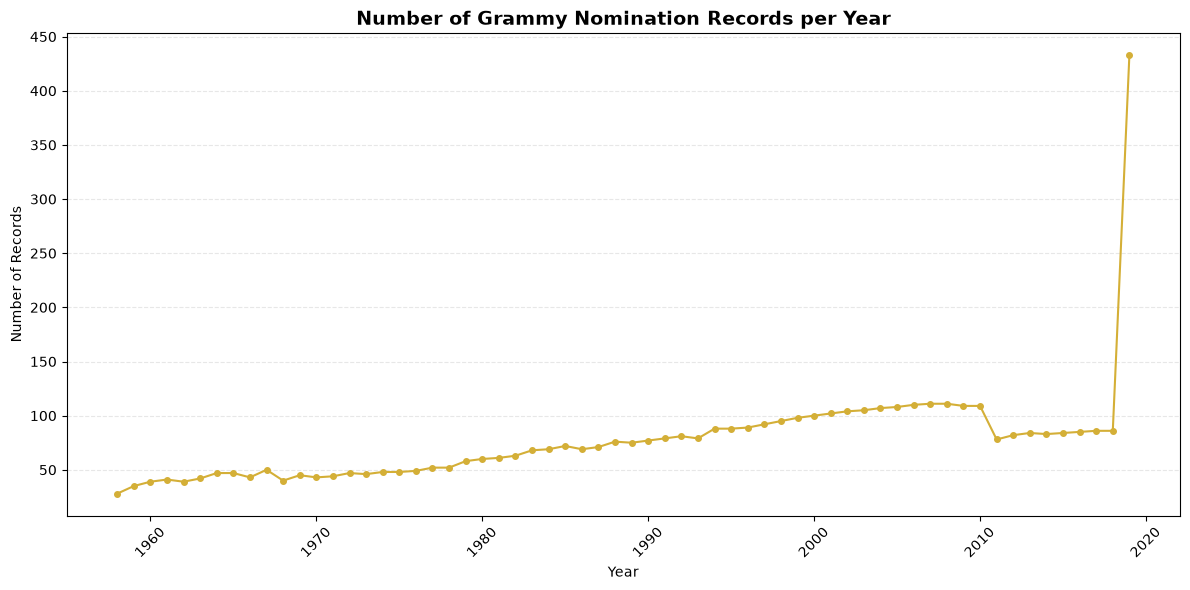

In [ ]:
nominations_per_year = pd.read_sql("""
    SELECT year, COUNT(*) AS nomination_count
    FROM awards
    GROUP BY year
    ORDER BY year
""", engine)

plt.figure(figsize=(12, 6))

plt.plot(
    nominations_per_year["year"],
    nominations_per_year["nomination_count"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    color="#D4AF37"
)

plt.title("Number of Grammy Nomination Records per Year",
          fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


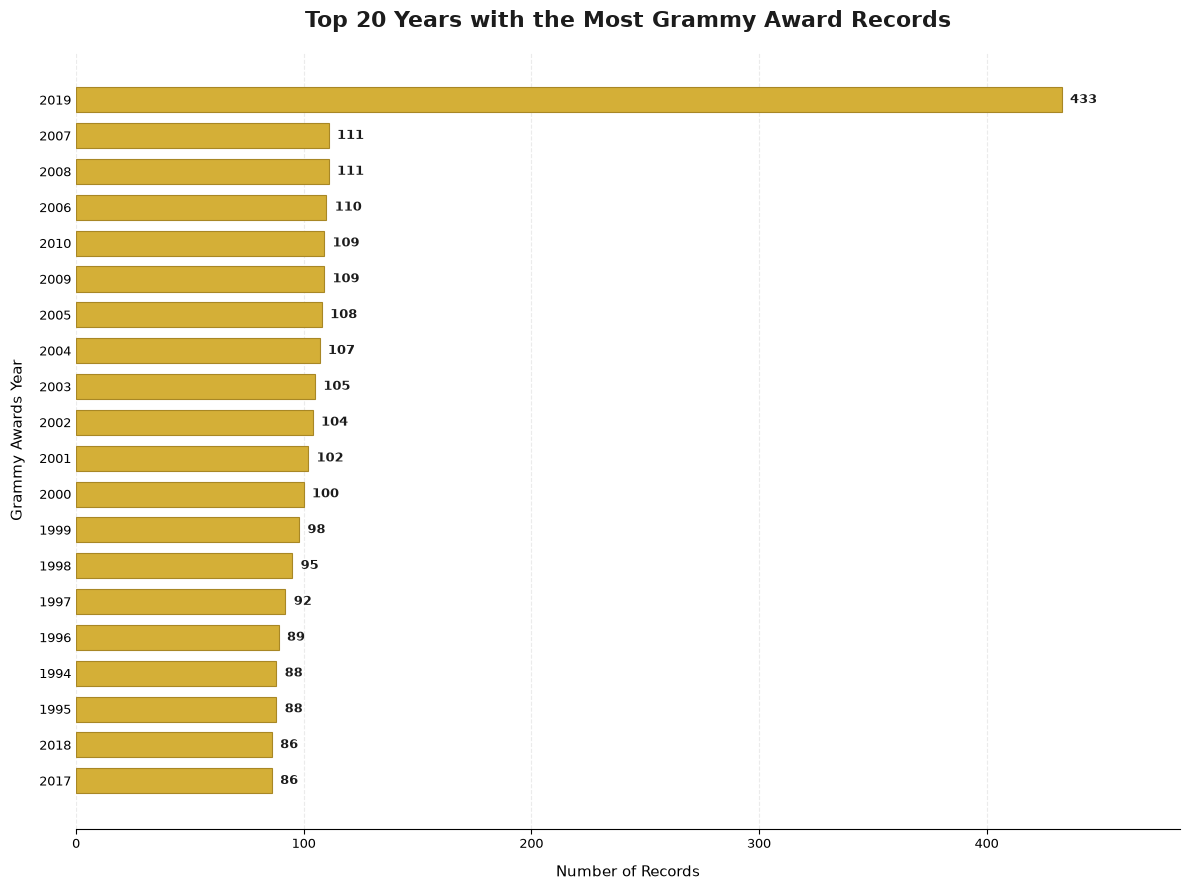

In [ ]:
query = text("""
    SELECT
        year,
        COUNT(*) AS total_records
    FROM grammys.awards
    GROUP BY year
    ORDER BY total_records DESC
    LIMIT 20;
""")

# Execute SQL query and load results into Pandas
df_top_years = pd.read_sql(query, engine)

# Sort ascending for horizontal bar chart
df_top_years = df_top_years.sort_values(
    "total_records",
    ascending=True
)

# Grammy-inspired colour palette
gold = "#D4AF37"
black = "#1C1C1C"
dark_gold = "#A88725"

# Create visualization
fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    df_top_years["year"].astype(str),
    df_top_years["total_records"],
    color=gold,
    edgecolor=dark_gold,
    linewidth=0.8,
    height=0.7
)

# Add numerical labels to each bar
ax.bar_label(
    bars,
    labels=[
        f"{value:,}"
        for value in df_top_years["total_records"]
    ],
    padding=6,
    fontsize=9,
    color=black,
    fontweight="bold"
)

# Titles and axis labels
ax.set_title(
    "Top 20 Years with the Most Grammy Award Records",
    fontsize=16,
    fontweight="bold",
    color=black,
    pad=18
)

ax.set_xlabel("Number of Records", fontsize=11, labelpad=10)
ax.set_ylabel("Grammy Awards Year", fontsize=11, labelpad=10)

# Clean chart styling
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Space for numerical labels
ax.set_xlim(
    0,
    df_top_years["total_records"].max() * 1.12
)

ax.tick_params(axis="y", labelsize=9, length=0)
ax.tick_params(axis="x", labelsize=9)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()



# Distribution of Grammy Award Records per Year

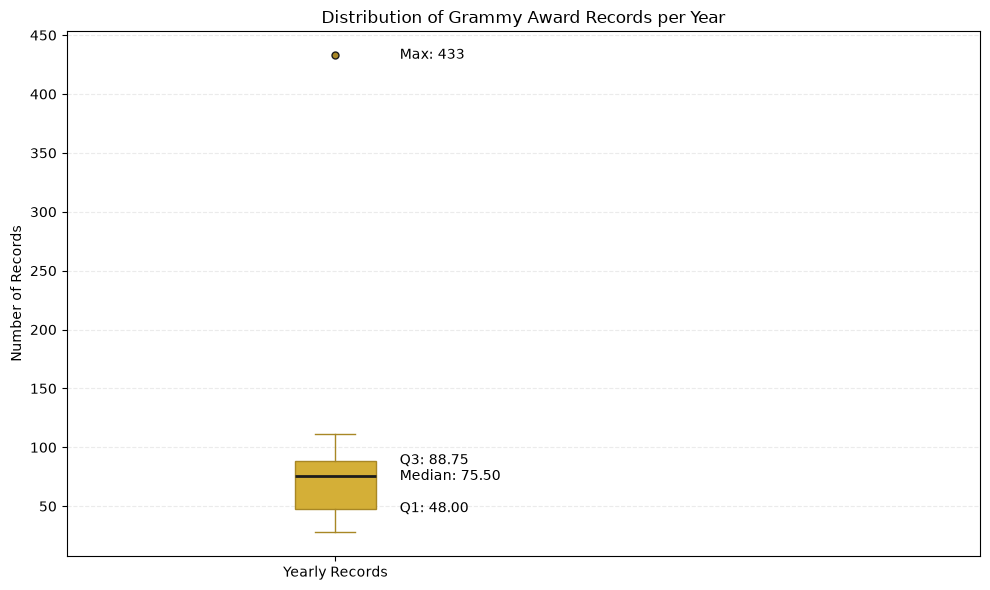

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

# Load yearly record counts from SQL into Pandas
query = text("""
    SELECT
        year,
        COUNT(*) AS total_records
    FROM grammys.awards
    GROUP BY year
    ORDER BY year;
""")

df_years = pd.read_sql(query, engine)

# Prepare data
data = df_years["total_records"].dropna()

# Calculate quartiles and maximum
Q1 = data.quantile(0.25)
median = data.median()
Q3 = data.quantile(0.75)
maximum = data.max()

# Grammy-inspired colours
gold = "#D4AF37"
black = "#1C1C1C"
dark_gold = "#A88725"

# Create boxplot
plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    patch_artist=True,
    boxprops=dict(facecolor=gold, color=dark_gold),
    medianprops=dict(color=black, linewidth=2),
    whiskerprops=dict(color=dark_gold),
    capprops=dict(color=dark_gold),
    flierprops=dict(
        marker="o",
        markerfacecolor=dark_gold,
        markeredgecolor=black,
        markersize=5
    )
)

# Display values beside the boxplot
plt.text(1.12, Q1, f"Q1: {Q1:,.2f}", va="center")
plt.text(1.12, median, f"Median: {median:,.2f}", va="center")
plt.text(1.12, Q3, f"Q3: {Q3:,.2f}", va="center")
plt.text(1.12, maximum, f"Max: {maximum:,.0f}", va="center")

# Titles and labels
plt.title("Distribution of Grammy Award Records per Year")
plt.ylabel("Number of Records")
plt.xticks([1], ["Yearly Records"])

# Leave space for labels
plt.xlim(0.5, 2.2)
plt.grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()



### Publication and Update Date Range

The dataset contains publication dates from November 2017 to May 2020, while update dates extend to September 2020.

**Finding:** Records were updated as late as September 2020, several months after the latest publication date.

- `published_at`: Date when the record was published on the platform (2017–2020).
- `updated_at`: Date when the record was last updated (2017–2020).

In [ ]:
print("Published At:")
print("Minimum:", df_awards["published_at"].min())
print("Maximum:", df_awards["published_at"].max())

print("\nUpdated At:")
print("Minimum:", df_awards["updated_at"].min())
print("Maximum:", df_awards["updated_at"].max())

Published At:
Minimum: 2017-11-28T00:03:45-08:00
Maximum: 2020-05-19T05:10:28-07:00

Updated At:
Minimum: 2017-11-28T00:03:45-08:00
Maximum: 2020-09-01T12:16:40-07:00


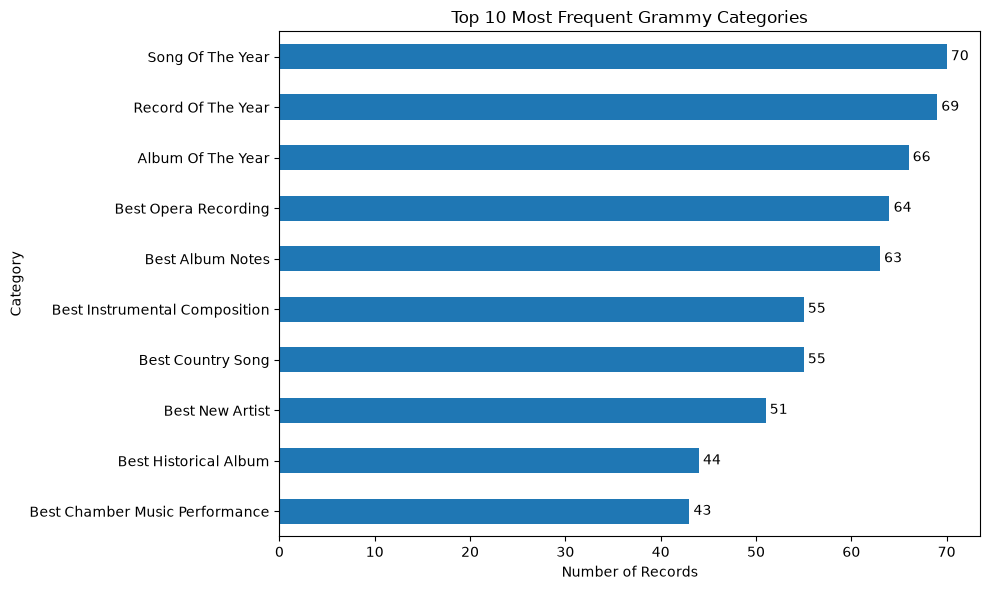

In [ ]:
# Frequency of each category
category_frequency = df_awards["category"].value_counts()

# Plot top 10 categories
ax = category_frequency.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

# Add labels
ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 Most Frequent Grammy Categories")
plt.xlabel("Number of Records")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### 📌 Variable Documentation: `nominee`

- **What does it store?**: Represents the **nominated/awarded work or entity**. Depending on the category, it stores:
  * **Songs / Singles** (e.g., *"Bad Guy"*).
  * **Albums / EPs** (e.g., *"Blackstar"*, *"7"*).
  * **Classical / Symphonic Works** (e.g., *"Berlioz: Requiem"*).
  * **Producer/Engineer Names** in technical classical music categories.
- **Purpose**: To identify the specific object or work for which the Grammy nomination or award was granted.

---

#### 📊 Statistical Summary (EDA)
- **Total records**: 4,810
- **Unique values**: 4,131
- **Null values**: 6 (0.12%) → *Occurs in categories without a specific work, such as "Remixer of the Year"*.
- **Name length**: 1 to 136 characters (Minimum: *"7"*, *"Sì"*).
- **Top Most Frequent**: 
  1. *Bridge Over Troubled Water* (7)
  2. *Robert Woods* (7)
  3. *Berlioz: Requiem* (7)

# Display 30 unique nominees from the Grammy Awards dataset

In [ ]:

query = """
    SELECT DISTINCT nominee
    FROM awards
    WHERE nominee IS NOT NULL
      AND TRIM(nominee) <> ''
    LIMIT 30;
"""

with engine.connect() as conn:
    nominees = pd.read_sql(query, conn)

nominees

,nominee
0,Bad Guy
1,"Hey, Ma"
2,7 rings
3,Hard Place
4,Talk
5,Old Town Road
6,Truth Hurts
7,Sunflower
8,"When We All Fall Asleep, Where Do We Go?"
9,"I,I"


In [ ]:
# Count the frequency of each nominee
query = """
    SELECT
        nominee,
        COUNT(*) AS frequency
    FROM awards
    WHERE nominee IS NOT NULL
      AND TRIM(nominee) <> ''
    GROUP BY nominee
    ORDER BY frequency DESC
    LIMIT 20;
"""

with engine.connect() as conn:
    top_20_nominees = pd.read_sql(query, conn)

top_20_nominees

,nominee,frequency
0,Bridge Over Troubled Water,7
1,Berlioz: Requiem,7
2,Robert Woods,7
3,Steven Epstein,7
4,David Frost,6
5,A Taste Of Honey,6
6,Britten: War Requiem,6
7,"Up, Up And Away",6
8,King Of The Road,5
9,Blackstar,5


In [ ]:
query = """
    SELECT
        nominee,
        category,
        COUNT(*) AS frequency
    FROM awards
    WHERE nominee IS NOT NULL
      AND TRIM(nominee) <> ''
    GROUP BY nominee, category
    HAVING COUNT(*) > 1
    ORDER BY frequency DESC, nominee
    LIMIT 30;
"""

with engine.connect() as conn:
    nominee_categories = pd.read_sql(query, conn)

nominee_categories

,nominee,category,frequency
0,David Frost,"Producer Of The Year, Classical",6
1,Robert Woods,Classical Producer Of The Year,6
2,Steven Epstein,"Producer Of The Year, Classical",5
3,Berg: Wozzeck,Best Opera Recording,4
4,Judith Sherman,"Producer Of The Year, Classical",4
5,Berlioz: Les Troyens,Best Opera Recording,3
6,Bizet: Carmen,Best Opera Recording,3
7,James Mallinson,Classical Producer Of The Year,3
8,Babyface,Producer Of The Year,2
9,Bartók: Concerto For Orchestra,Best Classical Performance - Orchestra,2


In [ ]:

query = """
    SELECT *
    FROM awards
    WHERE nominee IS NULL
       OR TRIM(nominee) = ''
    LIMIT 30;
"""

with engine.connect() as conn:
    nominee_categories = pd.read_sql(query, conn)

nominee_categories


,year,title,published_at,updated_at,category,nominee,artist,workers,img,winner
0,2000,43rd Annual GRAMMY Awards (2000),2017-11-28T00:03:45-08:00,2019-09-10T01:11:09-07:00,"Remixer of the Year, Non-Classical",,,,,True
1,1999,42nd Annual GRAMMY Awards (1999),2017-11-28T00:03:45-08:00,2019-09-10T01:09:02-07:00,"Remixer Of The Year, Non-Classical",,,,,True
2,1998,41st Annual GRAMMY Awards (1998),2017-11-28T00:03:45-08:00,2019-09-10T01:08:19-07:00,"Remixer Of The Year, Non-classical",,,,,True
3,1997,40th Annual GRAMMY Awards (1997),2017-11-28T00:03:45-08:00,2019-09-10T01:07:37-07:00,"Remixer Of The Year, Non-Classical",,,,,True
4,1965,8th Annual GRAMMY Awards (1965),2017-11-28T00:03:45-08:00,2019-09-10T01:06:59-07:00,Best New Country & Western Artist,,,,,True
5,1964,7th Annual GRAMMY Awards (1964),2017-11-28T00:03:45-08:00,2019-09-10T01:06:11-07:00,Best New Country & Western Artist Of 1964,,,,,True


### 📌 Variable Documentation: `workers`

- **What does it store?**: It stores the **technical, production, and creative credits** behind the nominated work. This includes roles such as producers, sound engineers, mixers, songwriters, composers, conductors, and arrangers, often formatted as text strings alongside names (e.g., *"John Williams, composer"* or *"Steve Earle, producer; Ray Kennedy, engineer"*).
- **Purpose**: To document the behind-the-scenes professionals, production teams, and masterminds contributing to the nominated song, album, or performance.

In [ ]:
# 1. Load the dataset from the existing MySQL table
df = pd.read_sql("SELECT * FROM awards", engine)

# 2. Define the list of roles to search for
roles = [
    'producer', 'engineer', 'mixer', 'songwriter',
    'composer', 'conductor', 'arranger',
    'mastering engineer', 'soloist'
]

# 3. Remove null values from the 'workers' column
workers_clean = df['workers'].dropna().astype(str)

# 4. Count the occurrences of each role
role_counts = {}

for role in roles:
    # case=False makes the search case-insensitive
    count = workers_clean.str.contains(
        role,
        case=False,
        regex=False
    ).sum()

    role_counts[role] = count

# 5. Convert the results into a DataFrame and sort by frequency
df_roles = (
    pd.DataFrame(
        list(role_counts.items()),
        columns=['Role', 'Frequency']
    )
    .sort_values(by='Frequency', ascending=False)
    .reset_index(drop=True)
)

# 6. Display the results
print(df_roles)

                 Role  Frequency
0            producer       1214
1            engineer        994
2               mixer        710
3          songwriter        298
4            composer        228
5           conductor        224
6            arranger        136
7  mastering engineer        114
8             soloist        104


```text
TOTAL UNIVERSE (4,810 Winners)
 │
 ├── Both Artist & Nominee: 2,970 (61.7%)
 │   └── Performance & Interpretation (Song + Artist/Band)
 │
 └── Nominee Only: 1,834 (38.1%)
     └── Authorship & Technical Categories (Composer, Arranger, Producer, etc.)

### 📖 Case Study: Understanding Award Recipients When `artist` is Null

In the Grammy Awards dataset, a null `artist` field **does not mean the data is broken**. Instead, it reflects the structural logic of awards focused on **authorship, composition, and production** rather than direct performance.

#### 🔍 How to Identify the Winner Without an `artist`?
When the `artist` column is empty (`NaN`), the recipient of the award is defined by combining two fields:
1. **`nominee`**: Specifies the name of the creative work, song, or album.
2. **`workers`**: Specifies the actual human beings who created the work and received the trophy (alongside their specific creative role).

---

### 💡 Real-World Examples

#### Example 1: Songwriting Category (*Song Of The Year*)
* **`category`**: *Song Of The Year*
* **`nominee`**: `"Bad Guy"` *(The Work/Song)*
* **`artist`**: `NaN` *(Null because the award goes to the writer, not the performing artist)*
* **`workers`**: `"Billie Eilish O'Connell & Finneas O'Connell, songwriters"` **← The actual winners of the Grammy trophy**

#### Example 2: Technical/Arrangement Category (*Best Instrumental Arrangement*)
* **`category`**: *Best Instrumental Arrangement*
* **`nominee`**: `"Moon River"` *(The Work)*
* **`artist`**: `NaN`
* **`workers`**: `"Vince Mendoza, arranger"` **← The actual winner in the role of arranger**

---

### 🛠️ ETL & Data Pipeline Implications
* **For "Both" Records**: The `artist` field represents the performer, and the match with streaming platforms (like Spotify) is straightforward.
* **For "Nominee only" + Workers Records (1,654 records)**: To correctly credit or merge these records, our ETL pipeline must extract the creator's name and role directly from the text string inside the **`workers`** column.

In [ ]:
import pandas as pd

# 1. Cargar el dataset
# df = pd.read_sql("SELECT * FROM awards", engine)

# 2. Reemplazar cadenas vacías o espacios por valores nulos (pd.NA)
columns_to_check = ["artist", "nominee", "workers"]
for column in columns_to_check:
    df[column] = df[column].replace(r"^\s*$", pd.NA, regex=True)

# 3. Mapear disponibilidad booleana de las 3 variables
has_artist = df["artist"].notna()
has_nominee = df["nominee"].notna()
has_workers = df["workers"].notna()

# 4. Clasificación Principal (Artist vs Nominee)
conditions = [
    has_artist & ~has_nominee,
    ~has_artist & has_nominee,
    has_artist & has_nominee,
    ~has_artist & ~has_nominee
]

labels = [
    "Artist only",
    "Nominee only",
    "Both artist and nominee",
    "Neither artist nor nominee"
]

df["record_type"] = pd.Series(pd.NA, index=df.index, dtype="object")
for condition, label in zip(conditions, labels):
    df.loc[condition, "record_type"] = label

# 5. Agregar la disponibilidad de 'workers'
df["has_workers"] = has_workers

# 6. Resumen General (Artist vs Nominee)
record_summary = (
    df["record_type"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis("Record Type")
    .reset_index(name="Frequency")
)

# 7. Resumen de 'Nominee only' cruzado con 'workers'
nominee_workers_breakdown = (
    df[df["record_type"] == "Nominee only"]["has_workers"]
    .value_counts()
    .rename(index={True: "Nominee + Workers", False: "Nominee ONLY (No Workers)"})
    .reset_index(name="Frequency")
    .rename(columns={"has_workers": "Sub-Category"})
)

print("--- 1. Artist and Nominee Availability ---")
print(record_summary.to_string(index=False))

print("\n--- 2. Breakdown of 'Nominee only' Records with Workers ---")
print(nominee_workers_breakdown.to_string(index=False))

--- 1. Artist and Nominee Availability ---
               Record Type  Frequency
               Artist only          0
              Nominee only       1834
   Both artist and nominee       2970
Neither artist nor nominee          6

--- 2. Breakdown of 'Nominee only' Records with Workers ---
             Sub-Category  Frequency
        Nominee + Workers       1654
Nominee ONLY (No Workers)        180


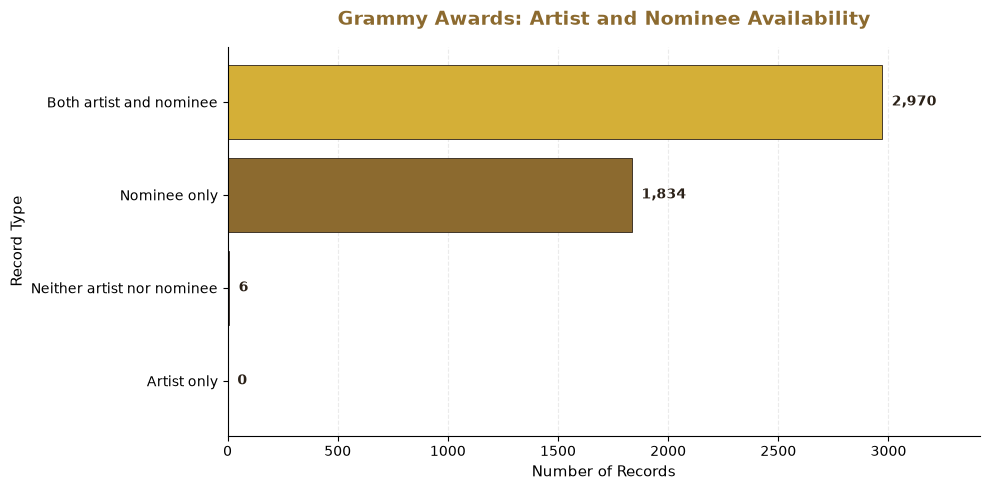

In [ ]:
# 1. Prepare the data
plot_df = record_summary.sort_values(
    by="Frequency",
    ascending=True
).copy()

# 2. Define Grammy-inspired colors
grammy_colors = {
    "Artist only": "#C9A227",
    "Nominee only": "#8C6A2F",
    "Both artist and nominee": "#D4AF37",
    "Neither artist nor nominee": "#6B7280"
}

colors = [
    grammy_colors[record_type]
    for record_type in plot_df["Record Type"]
]

# 3. Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_df["Record Type"],
    plot_df["Frequency"],
    color=colors,
    edgecolor="#2B2118",
    linewidth=0.6
)

# 4. Add frequency labels
max_frequency = plot_df["Frequency"].max()

for bar in bars:
    value = int(bar.get_width())

    ax.text(
        value + max_frequency * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#2B2118"
    )

# 5. Customize the chart
ax.set_title(
    "Grammy Awards: Artist and Nominee Availability",
    fontsize=14,
    fontweight="bold",
    color="#8C6A2F",
    pad=16
)

ax.set_xlabel("Number of Records", fontsize=11)
ax.set_ylabel("Record Type", fontsize=11)

ax.set_xlim(0, max_frequency * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# 1. Load the Grammy Awards dataset from MySQL
df = pd.read_sql("SELECT * FROM awards", engine)

print("=== 1. GENERAL VERIFICATION OF THE WINNER COLUMN ===")
print(f"Total rows in the dataset: {len(df)}")
print(f"Are all values in 'winner' True?: {df['winner'].all()}")
print(
    "Count of values in 'winner':\n"
    f"{df['winner'].value_counts(dropna=False)}\n"
)

# 2. Analyze the number of entries per category and year
# Group by year and category to count the records for each award category
entries_per_category = (
    df.groupby(["year", "category"])
    .size()
    .reset_index(name="num_entries")
)

# Separate the analysis before 2019 and for 2019
before_2019 = entries_per_category[
    entries_per_category["year"] < 2019
]

year_2019 = entries_per_category[
    entries_per_category["year"] == 2019
]

print("=== 2. ANALYSIS BEFORE 2019 (1958–2018) ===")
print(
    "Average entries per category: "
    f"{before_2019['num_entries'].mean():.2f}"
)
print(
    "Maximum entries in a category: "
    f"{before_2019['num_entries'].max()}"
)
print(
    "Note: Some years may contain only one record per category, "
    "but this must be verified using the actual data.\n"
)

print("=== 3. ANALYSIS FOR 2019 ===")
print(
    "Average entries per category in 2019: "
    f"{year_2019['num_entries'].mean():.2f}"
)
print(
    "Maximum entries in a category in 2019: "
    f"{year_2019['num_entries'].max()}"
)
print(
    "Note: Multiple nominees may be included in each category. "
    "Check the records to verify the actual number.\n"
)

# 4. Practical example: Record Of The Year (2019)
print("=== 4. EXAMPLE: RECORD OF THE YEAR (2019) ===")

roty_2019 = df[
    (df["year"] == 2019)
    & (df["category"] == "Record Of The Year")
]

print(
    roty_2019[
        ["category", "nominee", "artist", "winner"]
    ].to_string(index=False)
)

print(
    "\nObservation: Compare the winner values with the nominees "
    "to determine whether the column correctly identifies "
    "the actual winner."
)


=== 1. GENERAL VERIFICATION OF THE WINNER COLUMN ===
Total rows in the dataset: 4810
Are all values in 'winner' True?: True
Count of values in 'winner':
winner
True    4810
Name: count, dtype: int64

=== 2. ANALYSIS BEFORE 2019 (1958–2018) ===
Average entries per category: 1.01
Maximum entries in a category: 2
Note: Some years may contain only one record per category, but this must be verified using the actual data.

=== 3. ANALYSIS FOR 2019 ===
Average entries per category in 2019: 5.15
Maximum entries in a category in 2019: 8
Note: Multiple nominees may be included in each category. Check the records to verify the actual number.

=== 4. EXAMPLE: RECORD OF THE YEAR (2019) ===
          category       nominee                              artist winner
Record Of The Year       Bad Guy                       Billie Eilish   True
Record Of The Year       Hey, Ma                            Bon Iver   True
Record Of The Year       7 rings                       Ariana Grande   True
Record Of 

### Data Quality Finding — Historical Records vs. 2019 Entries

The number of records per category changes significantly in 2019 compared with previous years.

- **Before 2019 (1958–2018):** Categories contain an average of approximately 1.01 records, with a maximum of 2 records per category.
- **In 2019:** Categories contain an average of approximately 5.15 records, with a maximum of 8 records per category.

This difference may indicate inconsistent historical coverage or a change in the data collection methodology. Earlier years may primarily contain winner records, while 2019 may include multiple nominees per category.

However, this explanation has not yet been verified against the original data source. Additionally, the `winner` column contains only `True` values across all 4,810 records, preventing reliable identification of winners and nominees.

**Conclusion:** The increase in records per category in 2019 is a potential data consistency issue. Further validation against the original source is required before drawing conclusions about changes in Grammy nomination patterns over time.

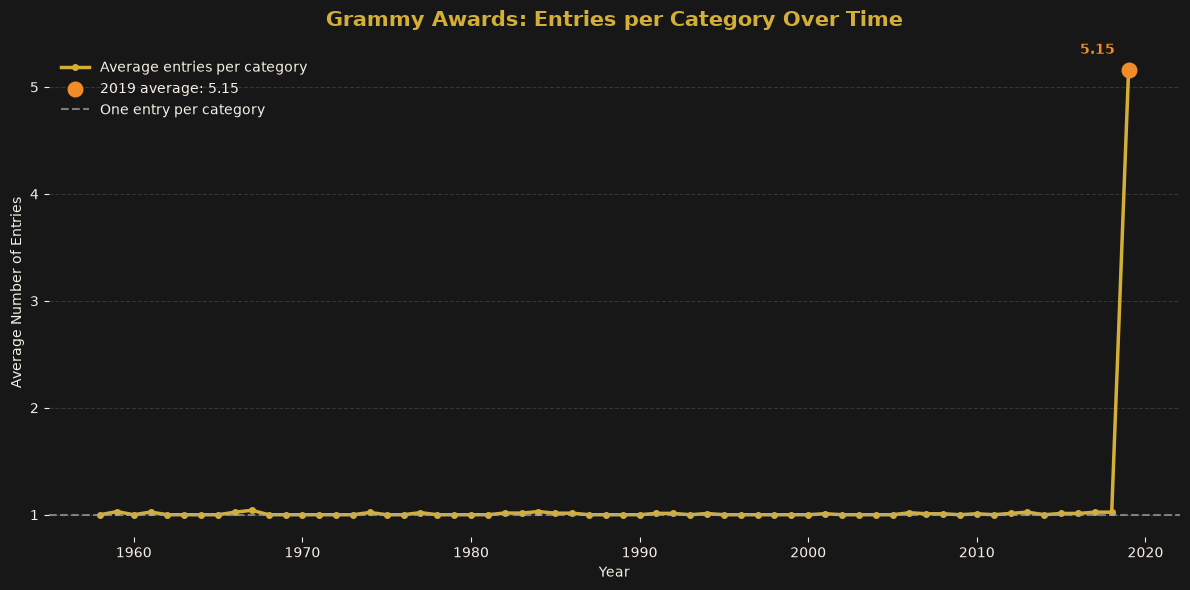

In [ ]:

# 1. Load the dataset from MySQL
df = pd.read_sql("SELECT * FROM awards", engine)

# 2. Count entries per category and year
entries_per_category = (
    df.groupby(["year", "category"])
    .size()
    .reset_index(name="num_entries")
)

# 3. Calculate the average number of entries per category each year
yearly_stats = (
    entries_per_category
    .groupby("year")["num_entries"]
    .mean()
    .reset_index(name="average_entries")
    .sort_values("year")
)

# 4. Define Grammy-inspired colors
background = "#171717"
gold = "#D4AF37"
orange = "#F28C28"
cream = "#F5F0E6"
gray = "#A7A7A7"

# 5. Create the line chart
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.plot(
    yearly_stats["year"],
    yearly_stats["average_entries"],
    color=gold,
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Average entries per category"
)

# 6. Highlight the year 2019
year_2019 = yearly_stats[yearly_stats["year"] == 2019]

if not year_2019.empty:
    x_2019 = year_2019["year"].iloc[0]
    y_2019 = year_2019["average_entries"].iloc[0]

    ax.scatter(
        x_2019,
        y_2019,
        color=orange,
        s=110,
        zorder=5,
        label=f"2019 average: {y_2019:.2f}"
    )

    ax.annotate(
        f"{y_2019:.2f}",
        (x_2019, y_2019),
        xytext=(-35, 12),
        textcoords="offset points",
        color=orange,
        fontweight="bold"
    )

# 7. Add a reference line
ax.axhline(
    y=1,
    color=gray,
    linestyle="--",
    alpha=0.7,
    label="One entry per category"
)

# 8. Customize the chart
ax.set_title(
    "Grammy Awards: Entries per Category Over Time",
    fontsize=15,
    fontweight="bold",
    color=gold,
    pad=16
)

ax.set_xlabel("Year", color=cream)
ax.set_ylabel("Average Number of Entries", color=cream)

ax.tick_params(colors=cream)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.legend(frameon=False, labelcolor=cream)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:

# Load the dataset from MySQL
df = pd.read_sql("SELECT * FROM awards", engine)

# Check the values in the winner column
print("Winner value counts:")
print(df["winner"].value_counts(dropna=False))

# Check the column data type
print("\nWinner column data type:")
print(df["winner"].dtype)


Winner value counts:
winner
True    4810
Name: count, dtype: int64

Winner column data type:
object


In [ ]:

# Inspect the actual values and their Python types
print("Unique values:")
print(df["winner"].unique())

print("\nPython types:")
print(df["winner"].map(type).value_counts())


Unique values:
['True']

Python types:
winner
<class 'str'>    4810
Name: count, dtype: int64


In [ ]:

query = text("""
    SELECT
        year,
        category,
        COUNT(*) AS total_records
    FROM grammys.awards
    WHERE year = 2019
    GROUP BY year, category
    ORDER BY total_records DESC;
""")

df_categories_2019 = pd.read_sql(query, engine)

df_categories_2019



,year,category,total_records
0,2019,Album Of The Year,8
1,2019,Song Of The Year,8
2,2019,Best New Artist,8
3,2019,Record Of The Year,8
4,2019,Best Contemporary Classical Composition,6
...,...,...,...
79,2019,Best Country Album,5
80,2019,Best Country Song,5
81,2019,Best Country Duo/Group Performance,5
82,2019,Best Country Solo Performance,5


In [ ]:

query = text("""
    SELECT
        year,
        category,
        nominee,
        artist,
        winner
    FROM grammys.awards
    WHERE year = 2019
      AND category IN (
          'Album Of The Year',
          'Song Of The Year',
          'Best New Artist',
          'Record Of The Year'
      )
    ORDER BY category, nominee;
""")

df_grammys_2019 = pd.read_sql(query, engine)

df_grammys_2019


,year,category,nominee,artist,winner
0,2019,Album Of The Year,7,Lil Nas X,True
1,2019,Album Of The Year,Cuz I Love You (Deluxe),Lizzo,True
2,2019,Album Of The Year,Father Of The Bride,Vampire Weekend,True
3,2019,Album Of The Year,I Used To Know Her,H.E.R.,True
4,2019,Album Of The Year,"I,I",Bon Iver,True
5,2019,Album Of The Year,Norman F***ing Rockwell!,Lana Del Rey,True
6,2019,Album Of The Year,"thank u, next",Ariana Grande,True
7,2019,Album Of The Year,"When We All Fall Asleep, Where Do We Go?",Billie Eilish,True
8,2019,Best New Artist,Billie Eilish,,True
9,2019,Best New Artist,Black Pumas,,True


In [ ]:

query = text("""
    SELECT
        year,
        COUNT(*) AS total_records,
        SUM(CASE WHEN winner = 'True' THEN 1 ELSE 0 END)
            AS winner_true,
        SUM(CASE WHEN winner = 'False' THEN 1 ELSE 0 END)
            AS winner_false
    FROM grammys.awards
    GROUP BY year
    ORDER BY year DESC;
""")

df_winners_by_year = pd.read_sql(query, engine)

df_winners_by_year.head(20)


,year,total_records,winner_true,winner_false
0,2019,433,433.0,0.0
1,2018,86,86.0,0.0
2,2017,86,86.0,0.0
3,2016,85,85.0,0.0
4,2015,84,84.0,0.0
5,2014,83,83.0,0.0
6,2013,84,84.0,0.0
7,2012,82,82.0,0.0
8,2011,78,78.0,0.0
9,2010,109,109.0,0.0


In [ ]:
query = text("""
    SELECT
        category,
        COUNT(*) AS frequency
    FROM grammys.awards
    WHERE year = 2019
    GROUP BY category
    ORDER BY frequency DESC, category;
""")

df_grammys_2019 = pd.read_sql(query, engine)

df_grammys_2019

,category,frequency
0,Album Of The Year,8
1,Best New Artist,8
2,Record Of The Year,8
3,Song Of The Year,8
4,Best Contemporary Classical Composition,6
...,...,...
79,Best Tropical Latin Album,5
80,Best Urban Contemporary Album,5
81,Best World Music Album,5
82,"Producer Of The Year, Classical",5


In [ ]:
query = text("""
    SELECT
        year,
        category,
        nominee,
        artist,
        winner,
        COUNT(*) OVER (
            PARTITION BY nominee
        ) AS frequency
    FROM grammys.awards
    WHERE category = 'Record Of The Year'
      AND year = 2019
    ORDER BY frequency DESC, nominee;
""")

df_record_of_the_year = pd.read_sql(query, engine)

df_record_of_the_year

,year,category,nominee,artist,winner,frequency
0,2019,Record Of The Year,7 rings,Ariana Grande,True,1
1,2019,Record Of The Year,Bad Guy,Billie Eilish,True,1
2,2019,Record Of The Year,Hard Place,H.E.R.,True,1
3,2019,Record Of The Year,"Hey, Ma",Bon Iver,True,1
4,2019,Record Of The Year,Old Town Road,Lil Nas X Featuring Billy Ray Cyrus,True,1
5,2019,Record Of The Year,Sunflower,Post Malone & Swae Lee,True,1
6,2019,Record Of The Year,Talk,Khalid,True,1
7,2019,Record Of The Year,Truth Hurts,Lizzo,True,1


In [ ]:
query = text("""
    SELECT
        year,
        category,
        nominee,
        artist,
        winner,
        COUNT(*) OVER (
            PARTITION BY nominee
        ) AS frequency
    FROM grammys.awards
    WHERE year = 2018
      AND category = 'Record Of The Year'
    ORDER BY nominee;
""")

df_record_of_the_year_2018 = pd.read_sql(query, engine)

df_record_of_the_year_2018

,year,category,nominee,artist,winner,frequency
0,2018,Record Of The Year,This Is America,Childish Gambino,True,1


In [ ]:
query = text("""
    SELECT
        year,
        category,
        nominee,
        artist,
        winner,
        COUNT(*) OVER (
            PARTITION BY nominee
        ) AS frequency
    FROM grammys.awards
    WHERE year = 2017
      AND category = 'Record Of The Year'
    ORDER BY nominee;
""")

df_record_of_the_year_2017 = pd.read_sql(query, engine)

df_record_of_the_year_2017

,year,category,nominee,artist,winner,frequency
0,2017,Record Of The Year,24K Magic,Bruno Mars,True,1


In [ ]:
query = text("""
    SELECT
        year,
        category,
        COUNT(*) AS total_nominees,
        GROUP_CONCAT(nominee SEPARATOR ' | ') AS nominees,
        GROUP_CONCAT(artist SEPARATOR ' | ') AS artists
    FROM grammys.awards
    WHERE year BETWEEN 1958 AND 2018
    GROUP BY year, category
    HAVING COUNT(*) = 2
    ORDER BY year, category;
""")

df_possible_ties = pd.read_sql(query, engine)

df_possible_ties

,year,category,total_nominees,nominees,artists
0,1959,Best Broadway Show Album,2,Gypsy | Redhead,|
1,1961,Best Contemporary Classical Composition,2,Almeida: Discantus | Stravinsky: Movements For...,|
2,1966,Best Classical Choral Performance (Other Than ...,2,Handel: Messiah | Ives: Music For Chorus,|
3,1967,"Album Of The Year, Classical",2,Mahler: Symphony No. 8 (Symphony Of A Thousand...,|
4,1967,Best Classical Choral Performance (Other Than ...,2,Orff: Catulli Carmina | Mahler: Symphony No. 8...,|
5,1974,Best Album Notes,2,The Hawk Flies | For The Last Time,|
6,1977,Song Of The Year,2,You Light Up My Life | Love Theme From A Star ...,|
7,1982,Best R&B Performance By A Duo Or Group With Vocal,2,Wanna Be With You | Let It Whip,"Earth, Wind & Fire | Dazz Band"
8,1983,Best Opera Recording,2,Mozart: Le Nozze Di Figaro | Verdi: La Traviata,|
9,1984,Best Instrumental Composition,2,The Natural | Olympic Fanfare & Theme,|
